![](https://images.thedirect.com/media/article_full/transformers-rise-of-the-beasts-runtime.jpg)

# Agenda

1. 什么是深度学习？
    - 深度学习架构
    - 分类问题与损失函数
    - 梯度下降
    - 数据处理
    - 线性层/全连接层
    - MLP

2. 关于大语言模型我们要了解什么？
    - 数据集处理
    - attention
    - transformer
    - BERT
    - GPT
3. 模型微调
    - Bert Adapter
    - prompt-tuning
    - llama / alpaca / Lora
3. 将大语言模型运用于工作的思考与尝试。

# 深度学习架构

深度学习的整体流程如图所示：

![](pic/深度学习架构图.png)

1. 数据集分为训练集、验证集和测试集。训练集用以训练深度学习模型；验证集用以评估模型结果，进而辅助模型调参；测试集用以模型的预测。一般而言，训练集、验证集与测试集的比例为7:2:1。

2. 训练过程：
    1. 将训练数据集中的数据传入模型
    2. 使用损失函数计算损失值。
    3. 使用优化器计算梯度并更新模型参数
    4. 使用验证数据集，进行模型准确度验证。

3. 推理过程:
    1. 使用测试数据集测试模型的准确度。


## 分类问题与损失函数

深度学习处理的问题大部分都是分类问题。
例如一张照片里的动物是猫、狗还是人？


![](pic/cat.jpg)

In [1]:
import torch
import torch.nn.functional as F

# 我们可以把 这个问题看成一个概率分布
# 说明：这个确定的概率分布一般被称为 targets，中文称为标签。这也是数据打标的由来
t1 = torch.tensor([1, 0, 0], dtype=torch.float16)  # 代表图片为猫
t2 = torch.tensor([0, 1, 0], dtype=torch.float16)  # 代表图片为狗
t3 = torch.tensor([0, 0, 1], dtype=torch.float16)  # 代表图片为人

In [2]:
# 图片输入 ->  神经网络 -> 输出一个长度与分类数量相同的向量 这个向量一般被称为 logits

# 假设通过神经网络 之后的输出是  1.7614, 0.1982, 0.0432
logits = torch.tensor([1.7614, 0.1982, 0.0432])
logits

tensor([1.7614, 0.1982, 0.0432])

In [3]:
# 通过Softmax 可以将值计算成概率分布，方便与targets 进行比较。
# 通过  Softmax 函数的转换，值的大小关系不发生改变。

output = F.softmax(logits, dim=-1)
print(output)
output.sum(dim=-1)

tensor([0.7200, 0.1508, 0.1292])


tensor(1.)

In [4]:
# 损失函数 交叉熵 用于表示两个概率分布的相似程度。值越低，表示两个概率分布约相似。
# pytorch 提供的 cross_entropy 里面包含了Softmax

loss = F.cross_entropy(logits, t1)
loss

tensor(0.3285)

In [5]:
logits1 = torch.tensor([2.7614, 0.1982, 0.432])
logits2 = torch.tensor([27.614, 1.982, 4.32])  # 将 logits1 中的值放大10倍
r1 = F.cross_entropy(logits1, t1)
r2 = F.cross_entropy(logits2, t1)
r1, r2

(tensor(0.1608), tensor(-0.))

总结：


1. 深度学习处理的问题大部分都是分类问题

2. 神经网络的输出值需要与分类数量相同（logits），然后使用 SoftMax算法可以将神经网络的输出转化成一个概率分布

3. 交叉熵可以比较两个概率分布的相似度，相似度称为loss。

4. 深度学习的过程是不断修改模型参数让loss值不断变小的过程。

## 梯度下降

- 深度学习在学什么？

- 我们如何让我们的 loss 值减少？深度学习到底在学什么？

![](pic/梯度下降.png)


1. 找到loss 的最小值，即找到整个损失函数的最小值。对于简单的函数可以通过求导的方式找到解析解。

2. 深度学习中使用一种名为梯度下降（gradient descent）的方法， 这种方法几乎可以优化所有深度学习模型。 它通过不断地在损失函数递减的方向上更新参数来降低误差。


3. 梯度下降的计算方式：

  - 根据设计好的模型，系统会构建一个计算图（computational graph）， 来跟踪计算是哪些数据通过哪些操作组合起来产生输出。 

  - 自动微分使系统能够随后反向传播梯度。 这里，反向传播（backpropagate）意味着跟踪整个计算图，填充关于每个参数的偏导数。

In [14]:
import torch
x = torch.arange(4.0, requires_grad=True)
print(x)

y = 2 * torch.dot(x, x)
print(y)

tensor([0., 1., 2., 3.], requires_grad=True)
tensor(28., grad_fn=<MulBackward0>)


In [15]:
y.backward()
x.grad

tensor([ 0.,  4.,  8., 12.])

## 数据处理

- 训练数据集 / 验证数据集 / 测试数据集

- 将数据转换成 向量（张量）

- 获取数据集的 targets用于计算 loss

In [16]:
# 图像分类数据集

# MNIST数据集 (LeCun et al., 1998) 是图像分类中广泛使用的数据集之一，但作为基准数据集过于简单。
# 我们将使用类似但更复杂的Fashion-MNIST数据集 (Xiao et al., 2017)。

import torch
import torchvision
from torch.utils import data
from torchvision import transforms
from d2l import torch as d2l

d2l.use_svg_display()

In [21]:
# 读取数据
trans = transforms.ToTensor()
mnist_train = torchvision.datasets.FashionMNIST(
    root="../data", train=True, transform=trans, download=True)  # 训练数据集
mnist_test = torchvision.datasets.FashionMNIST(
    root="../data", train=False, transform=trans, download=True)  # 测试数据集
len(mnist_train), len(mnist_test)


# 1. 每张图片形状 是 28 * 28
# 2. 第二个int 类型的数据代表图片的分类
mnist_train[1000][0].shape, mnist_train[1000][1]

(torch.Size([1, 28, 28]), 1)

In [22]:
# 读取小批量
batch_size = 16


def get_dataloader_workers():  # @save
    """使用4个进程来读取数据"""
    return 4


train_iter = data.DataLoader(mnist_train, batch_size, shuffle=True,
                             num_workers=get_dataloader_workers())


def get_fashion_mnist_labels(labels):  # @save
    """返回Fashion-MNIST数据集的文本标签"""
    text_labels = ['t-shirt', 'trouser', 'pullover', 'dress', 'coat',
                   'sandal', 'shirt', 'sneaker', 'bag', 'ankle boot']
    return [text_labels[int(i)] for i in labels]

torch.Size([16, 1, 28, 28]) torch.float32 torch.Size([16]) torch.int64
tensor([9, 9, 3, 9, 3, 8, 4, 0, 1, 9, 5, 9, 6, 9, 3, 3])


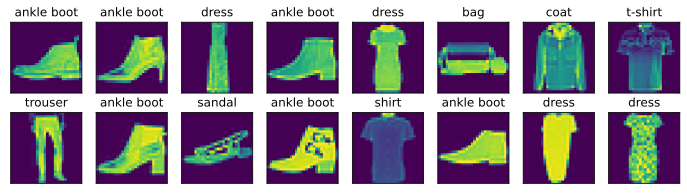

In [20]:
for x, y in train_iter:
    print(x.shape, x.dtype, y.shape, y.dtype)
    print(y)
    d2l.show_images(x.reshape(16, 28, 28), 2, 8,
                    titles=get_fashion_mnist_labels(y))
    break

## linear - 线性层/全连接层

![](https://zh-v2.d2l.ai/_images/softmaxreg.svg)

1. 输入矩阵为 (1 * m) 的矩阵， 输出是一个 (1, n) 的矩阵
2. 中的 W 为一个 (m * n) 的矩阵, b 是一个 (1, n) 的矩阵
3. o=𝐗𝐰+𝑏

In [14]:
import torch
from torch import nn
from d2l import torch as d2l

batch_size = 256
train_iter, test_iter = d2l.load_data_fashion_mnist(batch_size)

In [20]:
# PyTorch不会隐式地调整输入的形状。因此，是用nn.Flatten() 将28 * 28 变成784 长度的向量


net = nn.Sequential(nn.Flatten(), nn.Linear(784, 10))


def init_weights(m):
    if type(m) == nn.Linear:
        nn.init.normal_(m.weight, std=0.01)


net.apply(init_weights)
print(list(net.parameters()))
print(list(net.parameters())[0].shape, list(net.parameters())[1].shape)

[Parameter containing:
tensor([[-0.0172, -0.0104, -0.0013,  ..., -0.0035,  0.0010, -0.0053],
        [-0.0142, -0.0068,  0.0083,  ...,  0.0180,  0.0116, -0.0049],
        [-0.0137,  0.0104,  0.0112,  ...,  0.0107, -0.0015,  0.0120],
        ...,
        [ 0.0071,  0.0301, -0.0052,  ..., -0.0009, -0.0024,  0.0109],
        [-0.0019,  0.0140,  0.0052,  ..., -0.0119, -0.0038, -0.0138],
        [-0.0120,  0.0010,  0.0111,  ..., -0.0014,  0.0028,  0.0065]],
       requires_grad=True), Parameter containing:
tensor([ 0.0333,  0.0348, -0.0170,  0.0286, -0.0130, -0.0150,  0.0130,  0.0006,
         0.0276, -0.0137], requires_grad=True)]
torch.Size([10, 784]) torch.Size([10])


In [21]:
# Softmax + 交叉熵 作为损失函数
loss = nn.CrossEntropyLoss(reduction='none')

# 使用随机梯度下降
trainer = torch.optim.SGD(net.parameters(), lr=0.1)

In [22]:
def train_epoch(net, train_iter, loss, updater):
    net.train()
    metric = Accumulator(3)

    for X, y in train_iter:
        # 计算梯度并更新参数
        y_hat = net(X)
        l = loss(y_hat, y)
        if isinstance(updater, torch.optim.Optimizer):
            # 使用PyTorch内置的优化器和损失函数
            updater.zero_grad()
            l.mean().backward()
            updater.step()
        metric.add(float(l.sum()), accuracy(y_hat, y), y.numel())
    # 返回训练损失和训练精度
    return metric[0] / metric[2], metric[1] / metric[2]

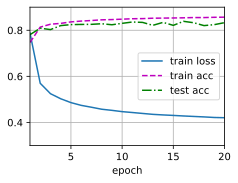

In [23]:
# 开始训练
def train_ch3(net, train_iter, test_iter, loss, num_epochs, updater):  # @save
    """训练模型"""
    animator = Animator(xlabel='epoch', xlim=[1, num_epochs], ylim=[0.3, 0.9],
                        legend=['train loss', 'train acc', 'test acc'])
    for epoch in range(num_epochs):
        train_metrics = train_epoch(net, train_iter, loss, updater)
        test_acc = evaluate_accuracy(net, test_iter)
        animator.add(epoch + 1, train_metrics + (test_acc,))
    train_loss, train_acc = train_metrics
    assert train_loss < 0.5, train_loss
    assert train_acc <= 1 and train_acc > 0.7, train_acc
    assert test_acc <= 1 and test_acc > 0.7, test_acc


num_epochs = 20
d2l.train_ch3(net, train_iter, test_iter, loss, num_epochs, trainer)

In [ ]:
list(net.parameters())

In [ ]:
# 进行预测
def predict(net, test_iter, n=10):  # @save
    """预测标签（定义见第3章）"""
    for X, y in test_iter:
        break
    trues = d2l.get_fashion_mnist_labels(y)
    preds = d2l.get_fashion_mnist_labels(net(X).argmax(axis=1))
    titles = [true + '\n' + pred for true, pred in zip(trues, preds)]
    d2l.show_images(
        X[0:n].reshape((n, 28, 28)), 1, 10, titles=titles[0:n])


predict(net, test_iter)

总结：

1. 通过 linear 层，我们可以将输出层 输出的元素数量与分类的类别数量保持一致。

2. 借助softmax 和交叉熵，我们可以训练多分类的模型。

2. 多数常见的深度学习模型都有类似的训练过程：先读取数据，再定义模型和损失函数，然后使用优化算法训练模型。




##  多层感知机-MLP 

![](https://zh-v2.d2l.ai/_images/mlp.svg)

1. 线性意味着单调假设： 任何特征的增大都会导致模型输出的增大（如果对应的权重为正）， 或者导致模型输出的减小（如果对应的权重为负）

2. 我们可以通过在网络中加入一个或多个隐藏层来克服线性模型的限制， 使其能处理更普遍的函数关系类型。 要做到这一点，最简单的方法是将许多全连接层堆叠在一起。 每一层都输出到上面的层，直到生成最后的输出。 我们可以把前层看作表示，把最后一层看作线性预测器。 这种架构通常称为多层感知机（multilayer perceptron），通常缩写为MLP。 下面，我们以图的方式描述了多层感知机

### 激活函数

1. 简单的将两个或者多个全连接层叠加在一起，等价于一个全连接层。 

2. 需要在每一个隐藏层使用非线性的激活函数，确保多层感知机不会退化成线性模型。

3. 常见激活函数
  - ReLU函数
  - sigmoid
  - tanh函数

https://zh-v2.d2l.ai/chapter_multilayer-perceptrons/mlp.html#id6


### MLP 实现

In [24]:
import torch
from torch import nn
from d2l import torch as d2l

train_iter, test_iter = d2l.load_data_fashion_mnist(batch_size)


# 定义超参
hidden_width = 256
lr = 0.1

# 定义训练变量
batch_size, num_epochs = 256, 20

net = nn.Sequential(nn.Flatten(),
                    nn.Linear(784, hidden_width),
                    nn.ReLU(),
                    nn.Linear(hidden_width, 10))


def init_weights(m):
    if type(m) == nn.Linear:
        nn.init.normal_(m.weight, std=0.01)


net.apply(init_weights)

loss = nn.CrossEntropyLoss(reduction='none')
trainer = torch.optim.SGD(net.parameters(), lr=lr)

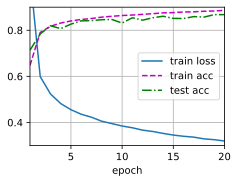

In [25]:
d2l.train_ch3(net, train_iter, test_iter, loss, num_epochs, trainer)

# 大语言模型


[大语言模型调研汇总](https://zhuanlan.zhihu.com/p/614766286)


- 语言模型如何将文字变成 计算机可以识别的向量？
- 注意力机制是什么？
- 主角 transformer
- 如何判断输出的好坏？
- BERT / GPT

**文本生成 本质上也是分类任务**

## tokenizer 构造输入


- tokenizer 工作的原理其实就是 tokenizer.vocab：字典，存储了 token => id 的映射关系

In [56]:
from transformers import AutoTokenizer, AutoConfig

model_name_or_path = "bert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(model_name_or_path)

# 字典
tokenizer.get_vocab()

{'ा': 1340,
 'baskets': 25946,
 'materialized': 27075,
 '##rrado': 27933,
 'improve': 5335,
 '##sford': 17658,
 'surfer': 27747,
 '[unused237]': 242,
 'quarterfinals': 9237,
 'screening': 11326,
 'fusiliers': 27207,
 '<': 1026,
 '##media': 16969,
 'bag': 4524,
 '##sam': 21559,
 'cabinets': 20053,
 'hot': 2980,
 'confusion': 6724,
 'judging': 13325,
 'descendant': 12608,
 'specifically': 4919,
 'scuba': 28651,
 'bail': 15358,
 'roommate': 18328,
 '1974': 3326,
 'boulder': 13264,
 'reverted': 16407,
 '##city': 12972,
 'promotional': 10319,
 '##with': 24415,
 'selma': 28112,
 'disappearance': 13406,
 'birth': 4182,
 'proportion': 10817,
 '##bee': 11306,
 'patterns': 7060,
 'forever': 5091,
 'ripped': 9157,
 'miniature': 12973,
 'gladstone': 21765,
 '##セ': 30234,
 '##atin': 20363,
 'minerva': 27383,
 'game': 2208,
 '##path': 15069,
 'cory': 18342,
 'distal': 29333,
 '##hang': 18003,
 'decisions': 6567,
 '##tc': 13535,
 'traps': 16735,
 'minogue': 27736,
 'incidence': 18949,
 'blackish': 22

In [57]:
print(tokenizer.special_tokens_map)


test_senteces = ['today is not that bad', 'today is so bad', 'so good']
batch_input = tokenizer(test_senteces, truncation=True, padding=True, return_tensors="pt")
print(batch_input)

{'unk_token': '[UNK]', 'sep_token': '[SEP]', 'pad_token': '[PAD]', 'cls_token': '[CLS]', 'mask_token': '[MASK]'}
{'input_ids': tensor([[ 101, 2651, 2003, 2025, 2008, 2919,  102],
        [ 101, 2651, 2003, 2061, 2919,  102,    0],
        [ 101, 2061, 2204,  102,    0,    0,    0]]), 'token_type_ids': tensor([[0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0]]), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1, 1, 0],
        [1, 1, 1, 1, 0, 0, 0]])}


In [58]:
encode = tokenizer.encode(test_senteces[0])
print(encode)

print(tokenizer.decode(encode))

[101, 2651, 2003, 2025, 2008, 2919, 102]
[CLS] today is not that bad [SEP]


In [59]:
config = AutoConfig.from_pretrained(model_name_or_path)

from torch import nn
token_embedding = nn.Embedding(config.vocab_size, config.hidden_size)
print(token_embedding)

print(token_embedding(batch_input['input_ids']).shape)

# [batch_size, sentence_lenth, hidden_states_size]

Embedding(30522, 768)
torch.Size([3, 7, 768])


## 注意力机制

![](https://zh-v2.d2l.ai/_images/qkv.svg)

![](02_动手学BERT_T5_GPT/imgs/scaled-dot-prod-attn.png)

### 多头注意力

![](https://zh-v2.d2l.ai/_images/multi-head-attention.svg)

In [60]:
from torch import nn
import torch

m = nn.Linear(20, 30)

# view 函数 - 修改形状  
# transpose 函数 - 变换维度
input = torch.rand(254,20)
output = m(input)
print(output.shape)
print(output.view(254,5,2,3).shape)
print(output.view(254,5,2,3).transpose(2,3).shape)

torch.Size([254, 30])
torch.Size([254, 5, 2, 3])
torch.Size([254, 5, 3, 2])


### QKV states 获取


- 输入数据 hidden_states

`[batch_size, sentence_lenth, hidden_states_size]`

- 线性层定义

一般情况下 num_heads * head_dim = hidden_size
```python
        self.q_proj = nn.Linear(self.hidden_size, self.num_heads * self.head_dim, bias=False)
        self.k_proj = nn.Linear(self.hidden_size, self.num_heads * self.head_dim, bias=False)
        self.v_proj = nn.Linear(self.hidden_size, self.num_heads * self.head_dim, bias=False)
```


- QKV
``` python
query_states = self.q_proj(hidden_states).view(bsz, q_len, self.num_heads, self.head_dim).transpose(1, 2)
key_states = self.k_proj(hidden_states).view(bsz, q_len, self.num_heads, self.head_dim).transpose(1, 2)
value_states = self.v_proj(hidden_states).view(bsz, q_len, self.num_heads, self.head_dim).transpose(1, 2)
```

- .view(bsz, q_len, self.num_heads, self.head_dim)

`[bsz, t, nh, hd]`

bsz: batch_size
t: sentence_len
nh: 多头注意力的数量
hd: head 的长度

nh * hd = embedding_len


- .transpose(1,2)

`[bsz, nh, t, hd]`

### pos_emb

```python
cos, sin = self.rotary_emb(value_states, seq_len=kv_seq_len)
query_states, key_states = apply_rotary_pos_emb(query_states, key_states, cos, sin, position_ids)
```

pos_emb 不改变形状


### attn_score / attn_weights

```python
attn_weights = torch.matmul(query_states, key_states.transpose(2, 3)) / math.sqrt(self.head_dim)

attn_weights = attn_weights + attention_mask
            attn_weights = torch.max(
                attn_weights, torch.tensor(torch.finfo(attn_weights.dtype).min, device=attn_weights.device)
            )

attn_weights = nn.functional.softmax(attn_weights, dim=-1, dtype=torch.float32).to(query_states.dtype)
```


- shape 的变化

`[bsz, nh, t, hd] * [bsz, nh, hd, t]  => [bsz, nh, t, t]` 

### attn_out_put

```
attn_output = torch.matmul(attn_weights, value_states)

attn_output = attn_output.transpose(1, 2)
attn_output = attn_output.reshape(bsz, q_len, self.hidden_size)

```


- attn_weights * V

`[bsz, nh, t, t] * [bsz, nh, t, hd]  =>  [bsz, nh, t, hd]`


- attn_output.transpose(1, 2)

`[bsz, nh, t, hd] => [bsz, t, nh, hd]`

- reshape

`[bsz, t, nh, hd] => [baz, t , nh * hd ]`


**输入形状与输出形状一致**


## transformer

![](https://pic1.zhimg.com/v2-f8d834e3e3387b67f81c8c8c20c3c34d_1440w.jpg?source=172ae18b)

- encoder / decoder 架构

- Positional Encoding

- masked multi-head attention


### Positional Encoding 

https://zh-v2.d2l.ai/chapter_attention-mechanisms/self-attention-and-positional-encoding.html#subsec-positional-encoding

### Add & Norm

```python
class BertSelfOutput(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.dense = nn.Linear(config.hidden_size, config.hidden_size)
        self.LayerNorm = nn.LayerNorm(config.hidden_size, eps=config.layer_norm_eps)
        self.dropout = nn.Dropout(config.hidden_dropout_prob)

    def forward(self, hidden_states: torch.Tensor, input_tensor: torch.Tensor) -> torch.Tensor:
        hidden_states = self.dense(hidden_states)
        hidden_states = self.dropout(hidden_states)
        hidden_states = self.LayerNorm(hidden_states + input_tensor)
        return hidden_states
```

- 在多头attn 之后添加了一个 Linear 层，输入输出的维度相同
- 将上一个全连接的输出 与多头attn的输入的hidden_states 相加。（input_tensor 是多头attn 输入的hidden_states）这个操作叫做Add
- 之后将数据传入layerNorm。

### Feed Forward + add & LayerNorm


- linear + 激活函数
```python
class BertIntermediate(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.dense = nn.Linear(config.hidden_size, config.intermediate_size)
        if isinstance(config.hidden_act, str):
            self.intermediate_act_fn = ACT2FN[config.hidden_act]
        else:
            self.intermediate_act_fn = config.hidden_act

    def forward(self, hidden_states: torch.Tensor) -> torch.Tensor:
        hidden_states = self.dense(hidden_states)
        hidden_states = self.intermediate_act_fn(hidden_states)
        return hidden_states
```

- feed_forward

```python
    def feed_forward_chunk(self, attention_output):
        intermediate_output = self.intermediate(attention_output)
        layer_output = self.output(intermediate_output, attention_output)
        return layer_output
```



### decoder
- decoder 与 encoder 相比，有两个特殊的 attention sublayers
    - masked multi-head (**self**) attention
    - encoder-decoder (**cross**) attention
        - (k, v) from encoder （memory, last encoder layer）
        - q：decoder input

### masked multi-head attention



In [61]:
from transformers import AutoTokenizer, AutoConfig, AutoModel
from torch import nn
import torch.nn.functional as F

model_ckpt = 'bert-base-uncased'
model = AutoModel.from_pretrained(model_ckpt)

tokenizer = AutoTokenizer.from_pretrained(model_ckpt)
config = AutoConfig.from_pretrained(model_ckpt)

Some weights of the model checkpoint at bert-base-uncased were not used when initializing BertModel: ['cls.seq_relationship.bias', 'cls.predictions.bias', 'cls.predictions.transform.dense.bias', 'cls.predictions.transform.LayerNorm.bias', 'cls.predictions.transform.dense.weight', 'cls.predictions.transform.LayerNorm.weight', 'cls.seq_relationship.weight']
- This IS expected if you are initializing BertModel from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertModel from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


In [ ]:
token_embedding = nn.Embedding(config.vocab_size, config.hidden_size)
# token_embedding
sample_text = 'time flies like an arrow'
model_inputs = tokenizer(sample_text, return_tensors='pt', add_special_tokens=False)
# forward of embedding module
input_embeddings = token_embedding(model_inputs['input_ids'])
# batch_size, seq_len, hidden_size
input_embeddings.shape

In [ ]:
import math
q = k = v = input_embeddings
# (1, 5, 768) * (1, 768, 5) => (1, 5, 5)
scores = torch.bmm(q, k.transpose(1, 2))/math.sqrt(k.size(-1))
scores

In [ ]:
def scaled_dot_product_attn(q, k, v, mask=None):
    # q, k, v: (b, s, h/a) (a: number heads, 12, 768/12=64)
    dim_k = k.size(-1)
    # b, s, s
    scores = torch.bmm(q, k.transpose(1, 2))/math.sqrt(dim_k)
    if mask is not None:
        scores.masked_fill_(mask == 0, -float('inf'))
    # 上对角值为 0 
    attn_weights = F.softmax(scores, dim=-1)
    print(attn_weights)
    return torch.bmm(attn_weights, v)

print(scaled_dot_product_attn(q, k, v, mask))

### BLUE

BLEU（双语评估替补）是一种用于评估从一种自然语言机器翻译成另一种自然语言的文本质量的算法。质量被认为是机器输出与人类输出之间的对应关系：“机器翻译越接近专业的人工翻译，它就越好”——这是 BLEU 背后的核心思想。 [1] 于 2001 年在 IBM 发明， [1] BLEU 是最早声称与人类质量判断高度相关的指标之一， [2] [3] 并且仍然是最受欢迎的自动化和廉价指标之一。

https://huggingface.co/spaces/evaluate-metric/bleu

## BERT

### summary
- bert: encoder of transformer
- transformer: encoder-decoder(seq2seq)
bert：
- embeddings
  - word(token) embedding
  - position embedding
  - token type embedding
- encoder(12 layer)
- self attention (kqv)
- feed forward
- pooler

In [16]:
from transformers import BertModel
from transformers import BertForSequenceClassification
import torch

model_name = "bert-base-uncased"  # bert base 12 层  / bert large 24 层
model = BertModel.from_pretrained(model_name)
model


Some weights of the model checkpoint at bert-base-uncased were not used when initializing BertModel: ['cls.seq_relationship.weight', 'cls.predictions.transform.LayerNorm.weight', 'cls.predictions.transform.dense.weight', 'cls.predictions.transform.LayerNorm.bias', 'cls.predictions.transform.dense.bias', 'cls.predictions.bias', 'cls.seq_relationship.bias']
- This IS expected if you are initializing BertModel from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertModel from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


BertModel(
  (embeddings): BertEmbeddings(
    (word_embeddings): Embedding(30522, 768, padding_idx=0)
    (position_embeddings): Embedding(512, 768)
    (token_type_embeddings): Embedding(2, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (encoder): BertEncoder(
    (layer): ModuleList(
      (0-11): 12 x BertLayer(
        (attention): BertAttention(
          (self): BertSelfAttention(
            (query): Linear(in_features=768, out_features=768, bias=True)
            (key): Linear(in_features=768, out_features=768, bias=True)
            (value): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (output): BertSelfOutput(
            (dense): Linear(in_features=768, out_features=768, bias=True)
            (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
            (dropout): Dropout(p=0.1, inplace=False)
  

In [17]:
total_params = 0
total_learn_params = 0

layer_total_params = dict()

for name, param in model.named_parameters():
    print(name,'->' ,param.size(), '-->', param.numel())
    total_params += param.numel()
    if param.requires_grad == True:
        total_learn_params += param.numel()
        
    layer = name.split(".")[0]
    if layer in layer_total_params:
        layer_total_params[layer] += param.numel() 
    else:
        layer_total_params[layer] = param.numel()

embeddings.word_embeddings.weight -> torch.Size([30522, 768]) --> 23440896
embeddings.position_embeddings.weight -> torch.Size([512, 768]) --> 393216
embeddings.token_type_embeddings.weight -> torch.Size([2, 768]) --> 1536
embeddings.LayerNorm.weight -> torch.Size([768]) --> 768
embeddings.LayerNorm.bias -> torch.Size([768]) --> 768
encoder.layer.0.attention.self.query.weight -> torch.Size([768, 768]) --> 589824
encoder.layer.0.attention.self.query.bias -> torch.Size([768]) --> 768
encoder.layer.0.attention.self.key.weight -> torch.Size([768, 768]) --> 589824
encoder.layer.0.attention.self.key.bias -> torch.Size([768]) --> 768
encoder.layer.0.attention.self.value.weight -> torch.Size([768, 768]) --> 589824
encoder.layer.0.attention.self.value.bias -> torch.Size([768]) --> 768
encoder.layer.0.attention.output.dense.weight -> torch.Size([768, 768]) --> 589824
encoder.layer.0.attention.output.dense.bias -> torch.Size([768]) --> 768
encoder.layer.0.attention.output.LayerNorm.weight -> torc

In [18]:
print("total_params: ", total_params)
print("total_learn_params: ", total_learn_params)
print(layer_total_params)

total_params:  109482240
total_learn_params:  109482240
{'embeddings': 23837184, 'encoder': 85054464, 'pooler': 590592}


### mlm


mlm任务：

在一个句子中，随机选中一定百分比（实际是15%）的token，将这些token用"[MASK]"替换。然后用分类模型预测"[MASK]"实际上是什么词；


In [19]:
from transformers import BertModel, BertTokenizer, BertForMaskedLM
mlm_model = BertForMaskedLM.from_pretrained(model_name, output_hidden_states=True)
tokenizer = BertTokenizer.from_pretrained(model_name)

Some weights of the model checkpoint at bert-base-uncased were not used when initializing BertForMaskedLM: ['cls.seq_relationship.weight', 'cls.seq_relationship.bias']
- This IS expected if you are initializing BertForMaskedLM from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertForMaskedLM from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


In [ ]:
text = """GitLab is an open source code repository and collaborative software development platform for large DevOps and DevSecOps projects. GitLab is free for individuals.
GitLab offers a location for online code storage and capabilities for issue tracking and CI/CD. The repository enables hosting different development chains and versions, and allows users to inspect previous code and roll back to it in the event of unforeseen problems.
GitLab is a competitor to GitHub, the code repository that hosts Linus Torvalds Linux kernel development, among many other projects. Because GitLab is developed on the same Git basis of version control, it functions very similarly for source code management.
GitLab provides end-to-end DevOps capabilities and for each stage of the software development lifecycle. GitLab’s continus integration (CI) capabilities enable development teams to automate building and testing their code. Security capabilities are included with scan results presented to the developer within their native CI pipeline/workflow, and a dashboard assists with vulnerability management for the security professional. Users can also take advantage of fuzz testing with GitLab's acquisitions of Peach Tech and Fuzzit. 
"""

token_input = tokenizer(text, return_tensors="pt")
' '.join(tokenizer.convert_ids_to_tokens(token_input['input_ids'][0]))


In [ ]:
token_input['labels'] = token_input['input_ids'].detach().clone()


# mask 测试
mask = torch.rand(token_input['input_ids'].shape) < 0.15

mask_arr = (torch.rand(token_input['input_ids'].shape) < 0.15) \
        * (token_input['input_ids'] != 101) \
        * (token_input['input_ids'] != 102)   
selection = torch.flatten(mask_arr[0].nonzero()).tolist()

token_input['input_ids'][0, selection] = tokenizer.vocab['[MASK]']
" ".join(tokenizer.convert_ids_to_tokens(token_input['input_ids'][0]))

In [ ]:
mlm_model.eval()

with torch.no_grad():
    mlm_output = mlm_model(**token_input)
    
mlm_output.keys()

In [63]:
logits = mlm_output['logits']
outputs = torch.argmax(logits[0], dim=1)
# 预测
print(tokenizer.convert_ids_to_tokens(outputs[selection]))

# 真实
print(tokenizer.convert_ids_to_tokens(token_input['labels'][0][selection]))

['##tl', 'is', 'meta', '##ab', 'and', 'x', 'and', 'allows', 'the', 'issues', '##us', '##ds', 'and', ',', 'it', 'end', '##ops', 'open', '##pl', '(', 'tools', 'auto', 'security', 'and', 'software', 'by', 'by', 'users', 'environment', 'with', 'developers', 'also', 'support', '##zz']
['##tl', 'is', 'dev', '##ab', 'and', 'cd', 'and', 'allows', 'previous', 'problems', '##us', '##ds', 'among', ',', 'it', 'end', '##ops', 'con', '##tin', '(', 'capabilities', 'auto', 'building', 'and', 'code', 'to', 'the', 'developer', 'pipeline', 'with', 'users', 'also', 'acquisitions', '##zzi']


### nsp

两个句子是否存在上下文关系

![](https://pic4.zhimg.com/80/v2-f1cf1213e3248ee11dcaf22330848573_1440w.webp)

In [27]:
text_1 = """GitLab is an open source code repository and collaborative software development platform for large DevOps and DevSecOps projects.
"""

text_2 = """GitLab offers a location for online code storage and capabilities for issue tracking and CI/CD.
"""

tokenizer(text_1,text_2)

{'input_ids': [101, 21025, 19646, 7875, 2003, 2019, 2330, 3120, 3642, 22409, 1998, 12317, 4007, 2458, 4132, 2005, 2312, 16475, 11923, 1998, 16475, 3366, 3597, 4523, 3934, 1012, 102, 21025, 19646, 7875, 4107, 1037, 3295, 2005, 3784, 3642, 5527, 1998, 9859, 2005, 3277, 9651, 1998, 25022, 1013, 3729, 1012, 102], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]}

###  整体流程总结

![](https://pic3.zhimg.com/80/v2-f26e2da9d210864efd881b3bdb6bfaee_1440w.webp)

## GPT

###  整体架构


- GPT 是transformer 的解码器。
- transformer-based language model 目前最核心的一个能力：text generation，尤其对于 gpt 而言；
- openai gpt2
  - https://openai.com/research/better-language-models
  - 预训练之后，被 prompt（context）激活的广泛的能力

|model        |参数量       |hidden dim        |  block 数量 | 
| ----------- |----------- | ---------------- | -----------| 
|gpt2         |124M        |    768  (64\*12) |          12|
|gpt2-medium  |355M        |    1024 (64\*16) |          24|
|gpt2-large   |774M        |    1280 (64\*20) |          36|
|gpt2-xl      |1.56B       |    1600 (64\*25) |          48|

In [1]:
import torch
from torch import nn
import transformers
from transformers import AutoTokenizer, AutoConfig, AutoModel, AutoModelForCausalLM
device = 'cuda' if torch.cuda.is_available() else 'cpu'

model_name = 'gpt2-xl'
model_clm = AutoModelForCausalLM.from_pretrained(model_name).to(device)
print(model_clm)

GPT2LMHeadModel(
  (transformer): GPT2Model(
    (wte): Embedding(50257, 1600)
    (wpe): Embedding(1024, 1600)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-47): 48 x GPT2Block(
        (ln_1): LayerNorm((1600,), eps=1e-05, elementwise_affine=True)
        (attn): GPT2Attention(
          (c_attn): Conv1D()
          (c_proj): Conv1D()
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (resid_dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_2): LayerNorm((1600,), eps=1e-05, elementwise_affine=True)
        (mlp): GPT2MLP(
          (c_fc): Conv1D()
          (c_proj): Conv1D()
          (act): NewGELUActivation()
          (dropout): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm((1600,), eps=1e-05, elementwise_affine=True)
  )
  (lm_head): Linear(in_features=1600, out_features=50257, bias=False)
)


In [2]:
# 预测时候一次只生成一个字符

input_txt = "A long long time ago,"

tokenizer = AutoTokenizer.from_pretrained(model_name)
model_inputs = tokenizer(input_txt,return_tensors='pt')

model_clm.eval()



with torch.re
input_ids = model_inputs['input_ids'].to(device)
output = model_clm(input_ids=input_ids)
last_token_logits = output.logits[0, -1, :]
token_id=last_token_logits.argmax(dim=-1)
print(tokenizer.decode(token_id))


SyntaxError: expected ':' (1637830590.py, line 12)

### 贪心算法与束搜索


https://zh.d2l.ai/chapter_recurrent-modern/beam-search.html

In [84]:
prompt = 'In a shocking finding, scientist discovered a herd of unicorns living in a remote, previously unexplored valley, in the Andes Mountains. Even more surprising to the researchers was the fact that the unicorns spoke perfect English.'
input_ids = tokenizer(prompt, return_tensors='pt').input_ids.to(device)

gen = model_clm.generate(input_ids, max_length=256, do_sample=False)
print(tokenizer.decode(gen[0]))

The attention mask and the pad token id were not set. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.
Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.


In a shocking finding, scientist discovered a herd of unicorns living in a remote, previously unexplored valley, in the Andes Mountains. Even more surprising to the researchers was the fact that the unicorns spoke perfect English.

The researchers, from the University of California, Davis, and the University of Colorado, Boulder, were conducting a study on the Andean cloud forest, which is home to the rare species of cloud forest trees.

The researchers were conducting a study on the Andean cloud forest, which is home to the rare species of cloud forest trees.

The researchers were conducting a study on the Andean cloud forest, which is home to the rare species of cloud forest trees.

The researchers were conducting a study on the Andean cloud forest, which is home to the rare species of cloud forest trees.

The researchers were conducting a study on the Andean cloud forest, which is home to the rare species of cloud forest trees.

The researchers were conducting a study on the Andean 

In [85]:
gen2 = model_clm.generate(input_ids, max_length=256, num_beams=7, do_sample=False)
print(tokenizer.decode(gen2[0]))

The attention mask and the pad token id were not set. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.
Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.


In a shocking finding, scientist discovered a herd of unicorns living in a remote, previously unexplored valley, in the Andes Mountains. Even more surprising to the researchers was the fact that the unicorns spoke perfect English.

The discovery of the unicorns was made by a team of scientists from the University of California, Davis, and the University of Colorado, Boulder.

The scientists were studying the Andes Mountains in South America when they discovered a herd of unicorns living in a remote, previously unexplored valley, in the Andes Mountains.

The scientists were studying the Andes Mountains in South America when they discovered a herd of unicorns living in a remote, previously unexplored valley, in the Andes Mountains. The scientists were studying the Andes Mountains in South America when they discovered a herd of unicorns living in a remote, previously unexplored valley, in the Andes Mountains. The scientists were studying the Andes Mountains in South America when they disc

# 模型微调

## Adapter


https://zh-v2.d2l.ai/chapter_natural-language-processing-applications/finetuning-bert.html
    


In [6]:
from transformers import AutoModelWithHeads, AutoTokenizer

modle_name = "bert-base-uncased"
model = AutoModelWithHeads.from_pretrained(modle_name)
adapter_name = model.load_adapter("AdapterHub/bert-base-uncased-pf-imdb", source="hf")
model.active_adapters = adapter_name

print(model)

/root/miniconda3/envs/pytorch2-0/lib/python3.10/site-packages/transformers/adapters/models/bert/adapter_model.py:269: FutureWarning: This class has been renamed to `BertAdapterModel` in v3. Please use the new class instead as this class might be removed in a future version.
  warnings.warn(
/root/miniconda3/envs/pytorch2-0/lib/python3.10/site-packages/transformers/adapters/models/bert/adapter_model.py:247: FutureWarning: This class has been renamed to `BertAdapterModel` in v3. Please use the new class instead as this class might be removed in a future version.
  warnings.warn(
Some weights of the model checkpoint at bert-base-uncased were not used when initializing BertModelWithHeads: ['cls.seq_relationship.weight', 'cls.predictions.bias', 'cls.predictions.transform.LayerNorm.weight', 'cls.predictions.transform.dense.weight', 'cls.predictions.transform.dense.bias', 'cls.seq_relationship.bias', 'cls.predictions.transform.LayerNorm.bias']
- This IS expected if you are initializing BertMo

Fetching 6 files:   0%|          | 0/6 [00:00<?, ?it/s]

BertModelWithHeads(
  (shared_parameters): ModuleDict()
  (bert): BertModel(
    (shared_parameters): ModuleDict()
    (invertible_adapters): ModuleDict()
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(
                in_features=768, out_features=768, bias=True
                (loras): ModuleDict()
              )
              (key): Linear(
                in_features=768, out_features=768, bias=True
                (loras): ModuleDict()
              )
              (value): Linear(
                in_features=768, out_fea

In [12]:
tokenizer = AutoTokenizer.from_pretrained(modle_name)

text1 = '''I like this movie'''
text_input_1 = tokenizer(text1, return_tensors="pt")

print(model(**text_input_1))


text2 = '''this movie is so ugly'''
text_input_2 = tokenizer(text2, return_tensors="pt")

print(model(**text_input_2))



SequenceClassifierOutput(loss=None, logits=tensor([[-2.9108,  3.0272]], grad_fn=<AddmmBackward0>), hidden_states=None, attentions=None)
SequenceClassifierOutput(loss=None, logits=tensor([[ 2.7112, -2.4181]], grad_fn=<AddmmBackward0>), hidden_states=None, attentions=None)


## lora

![](https://picx.zhimg.com/v2-ab70f0472cb75ce6dcf439ee0bc2f593_1440w.jpg?source=172ae18b)

In [2]:
import transformers
from transformers import (
    CONFIG_MAPPING,
    MODEL_FOR_CAUSAL_LM_MAPPING,
    AutoConfig,
    AutoModelForCausalLM,
    LlamaForCausalLM,
    LlamaTokenizer,
    AutoTokenizer,
    HfArgumentParser,
    Trainer,
    TrainingArguments,
    set_seed,
)
from peft import LoraConfig, TaskType, get_peft_model, PeftModel, get_peft_model_state_dict
import torch

model_name_or_path = "/data/models/llama-alpaca-plus-7B"
tokenizer_name_or_path = "/root/SourceCode/DL/Chinese-LLaMA-Alpaca/scripts/merged_tokenizer_sp/chinese_llama.model"
torch_dtype = torch.float16

In [6]:
# 加载基础模型
config = AutoConfig.from_pretrained(model_name_or_path)
tokenizer = LlamaTokenizer.from_pretrained(model_name_or_path)
cache_dir = None

lr=1e-4
lora_rank=8
lora_alpha=32
lora_trainable="q_proj,v_proj,k_proj,o_proj,gate_proj,down_proj,up_proj"
# modules_to_save="embed_tokens,lm_head"
lora_dropout=0.05
max_seq_length=512
cache_dir = None
model_revision = "main"
output_dir = "/data/chinese-llama/chinese_alpaca_plus_lora_7b_gitlab2"

model = LlamaForCausalLM.from_pretrained(
    model_name_or_path,
    from_tf=bool(".ckpt" in model_name_or_path),
    config=config,
    cache_dir=cache_dir,
    revision=model_revision,
    use_auth_token=None,
    torch_dtype=torch_dtype,
    low_cpu_mem_usage=True
)

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

In [9]:
model = LlamaForCausalLM.from_pretrained(
    model_name_or_path,
    from_tf=bool(".ckpt" in model_name_or_path),
    config=config,
    cache_dir=cache_dir,
    revision=model_revision,
    use_auth_token=None,
    torch_dtype=torch_dtype,
    low_cpu_mem_usage=True
)
target_modules = lora_trainable.split(',')
peft_config = LoraConfig(
    task_type=TaskType.CAUSAL_LM,
    target_modules=target_modules,
    inference_mode=False, 
    r=lora_rank, lora_alpha=lora_alpha, 
    lora_dropout=lora_dropout,
    modules_to_save=None)

model = get_peft_model(model, peft_config)
model

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

PeftModelForCausalLM(
  (base_model): LoraModel(
    (model): LlamaForCausalLM(
      (model): LlamaModel(
        (embed_tokens): Embedding(49954, 4096, padding_idx=0)
        (layers): ModuleList(
          (0-31): 32 x LlamaDecoderLayer(
            (self_attn): LlamaAttention(
              (q_proj): Linear(
                in_features=4096, out_features=4096, bias=False
                (lora_dropout): ModuleDict(
                  (default): Dropout(p=0.05, inplace=False)
                )
                (lora_A): ModuleDict(
                  (default): Linear(in_features=4096, out_features=8, bias=False)
                )
                (lora_B): ModuleDict(
                  (default): Linear(in_features=8, out_features=4096, bias=False)
                )
                (lora_embedding_A): ParameterDict()
                (lora_embedding_B): ParameterDict()
              )
              (k_proj): Linear(
                in_features=4096, out_features=4096, bias=False
        

In [12]:
# 可训练的参数
model.print_trainable_parameters()

trainable params: 19988480 || all params: 6905483264 || trainable%: 0.28945809056123434


# 大语言模型运用于工作的思考与尝试


1. 知识图谱  
2. issue 的总结归纳
3. issue 分类



学习路径：

- https://gitlab-cs.yuque.com/wv5xhe/vfbgp0